In [ ]:
import os
from pathlib import Path

BASE_DIR = Path.cwd()
DOCUMENTS_DIR = BASE_DIR / "data" / "documents"
LOGS_DIR = BASE_DIR / "logs"
TRACE_FILE = LOGS_DIR / "agent_trace.jsonl"

# DOCUMENTS_DIR.mkdir(parents=True, exist_ok=True)
# LOGS_DIR.mkdir(parents=True, exist_ok=True)

print("Notebook working directory:", BASE_DIR)
print("Documents directory:", DOCUMENTS_DIR)
print("Trace file:", TRACE_FILE)

Notebook working directory: c:\Users\Lenovo\Desktop\GUVI_2026\Interview
Documents directory: c:\Users\Lenovo\Desktop\GUVI_2026\Interview\data\documents
Trace file: c:\Users\Lenovo\Desktop\GUVI_2026\Interview\logs\agent_trace.jsonl


# 3.Configure the OpenAI API key

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")


# 4. Create sample local documents

In [8]:
sample_documents = {
    "company.txt": """Company Name: TechNova AI

TechNova AI develops artificial intelligence applications.

The company focuses on Machine Learning,
Generative AI, NLP and automation.

The company was established in 2020.

Employee Count: 150
""",
    "products.md": """# Products

## AI Platform

The AI platform supports machine learning model development.

## Chatbot

The chatbot uses Large Language Models.

It supports document search and retrieval augmented generation.

## Analytics

The analytics platform processes business data.
""",
    "policies.txt": """# Company Policies

Employees receive 20 days of annual leave.

The company provides remote work opportunities.

The standard working hours are 9 AM to 6 PM.

The company provides learning and development opportunities.
""",
}

for filename, content in sample_documents.items():
    (DOCUMENTS_DIR / filename).write_text(content, encoding="utf-8")

print("Created sample files:")
for path in sorted(DOCUMENTS_DIR.iterdir()):
    print("-", path.name)

Created sample files:
- cars_sold_in_india.txt
- company.txt
- elon_musk_achievements.pdf
- policies.txt
- Probability_and_Statistics_Concepts.docx
- products.md


# 5. Define JSON-schema tool arguments

Pydantic models generate JSON schemas that are attached to the LangChain tools.

In [11]:
from pydantic import BaseModel, Field

class SearchFilesInput(BaseModel):
    query: str = Field(
        description="Keyword or phrase to search inside .txt and .md files."
    )

class ReadFileInput(BaseModel):
    path: str = Field(
        description="Relative path of a document inside the documents folder."
    )

class CalculateInput(BaseModel):
    expression: str = Field(
        description="Arithmetic expression, for example (100 + 50) * 2."
    )

In [ ]:
# model_json_schema -> Pydantic method that converts a Pydantic model into a JSON Schema dictionary.
tool_schemas = {
    "search_files": SearchFilesInput.model_json_schema(),           
    "read_file": ReadFileInput.model_json_schema(),
    "calculate": CalculateInput.model_json_schema(),
}

import json

for name, schema in tool_schemas.items():
    print(f"\\n{name} JSON schema:")
    print(json.dumps(schema, indent=2))

\nsearch_files JSON schema:
{
  "properties": {
    "query": {
      "description": "Keyword or phrase to search inside .txt and .md files.",
      "title": "Query",
      "type": "string"
    }
  },
  "required": [
    "query"
  ],
  "title": "SearchFilesInput",
  "type": "object"
}
\nread_file JSON schema:
{
  "properties": {
    "path": {
      "description": "Relative path of a document inside the documents folder.",
      "title": "Path",
      "type": "string"
    }
  },
  "required": [
    "path"
  ],
  "title": "ReadFileInput",
  "type": "object"
}
\ncalculate JSON schema:
{
  "properties": {
    "expression": {
      "description": "Arithmetic expression, for example (100 + 50) * 2.",
      "title": "Expression",
      "type": "string"
    }
  },
  "required": [
    "expression"
  ],
  "title": "CalculateInput",
  "type": "object"
}


# 6. Implement the three tools

- Search is case-insensitive and returns matching lines with relative filenames and line numbers.

In [ ]:
from langchain.tools import tool
import json


@tool(args_schema=SearchFilesInput)
def search_files(query: str) -> str:
    """Search keyword matches in .txt and .md files under the documents folder."""
    if not query or not query.strip():
        return json.dumps({"error": "Search query cannot be empty."})

    matches = []
    for file_path in DOCUMENTS_DIR.rglob("*"):          # rglob -> It searches through the specified directory and all its subdirectories.
        if not file_path.is_file() or file_path.suffix.lower() not in {".txt", ".md"}:
            continue

        try:
            content = file_path.read_text(encoding="utf-8", errors="replace")
        except OSError as exc:
            # A file that cannot be read is skipped; it is not treated as a match.
            continue

        for line_number, line in enumerate(content.splitlines(), start=1):
            if query.casefold() in line.casefold():
                matches.append({
                    "file": str(file_path.relative_to(DOCUMENTS_DIR)),
                    "line_number": line_number,
                    "matching_line": line.strip(),
                })

    return json.dumps({
        "query": query,
        "total_matches": len(matches),
        "results": matches,
        "message": "Matches found" if matches else "No matching results found",
    })


- Read resolves the requested path and verifies that it remains inside the allowed document directory. This also blocks traversal through symlinks.

In [ ]:
from langchain.tools import tool
import json

@tool(args_schema=ReadFileInput)
def read_file(path: str) -> str:
    """Read a .txt or .md file, rejecting paths outside the documents folder."""
    try:
        root = DOCUMENTS_DIR.resolve(strict=True)
        requested = Path(path)

        # Relative paths are interpreted relative to the allowed documents folder.
        candidate = requested if requested.is_absolute() else root / requested
        resolved = candidate.resolve(strict=True)

        # Path.is_relative_to is available in Python 3.9+.
        if not resolved.is_relative_to(root):
            return json.dumps({
                "error": "Path traversal rejected: access outside the documents folder is forbidden."
            })

        if not resolved.is_file():
            return json.dumps({"error": "Requested path is not a file."})

        if resolved.suffix.lower() not in {".txt", ".md"}:
            return json.dumps({"error": "Only .txt and .md files are supported."})

        content = resolved.read_text(encoding="utf-8", errors="replace")
        return json.dumps({
            "file": str(resolved.relative_to(root)),
            "content": content,
        })

    except FileNotFoundError:
        return json.dumps({"error": "File not found."})
    except (OSError, ValueError) as exc:
        return json.dumps({"error": f"Could not read file: {exc}"})


- The calculator parses an expression into an AST and evaluates only numeric constants and approved arithmetic operators. It never calls `eval()`.

In [ ]:
import ast

import operator

# AST - Abstract Syntax Tree

# Operators explicitly permitted by the calculator.
ALLOWED_BINARY_OPERATORS = {
    ast.Add: operator.add,
    ast.Sub: operator.sub,
    ast.Mult: operator.mul,
    ast.Div: operator.truediv,
    ast.FloorDiv: operator.floordiv,
    ast.Mod: operator.mod,
    ast.Pow: operator.pow,
}
ALLOWED_UNARY_OPERATORS = {
    ast.UAdd: operator.pos,
    ast.USub: operator.neg,
}

def _safe_evaluate(node, depth=0):
    # Limit nesting to avoid deeply nested expressions.
    if depth > 30:
        raise ValueError("Expression is too deeply nested.")

    if isinstance(node, ast.Expression):
        return _safe_evaluate(node.body, depth + 1)

    if isinstance(node, ast.Constant):
        if type(node.value) not in (int, float):
            raise ValueError("Only numeric constants are allowed.")
        if abs(node.value) > 10**12:
            raise ValueError("Numeric literal is too large.")
        return node.value

    if isinstance(node, ast.BinOp):
        operator_type = type(node.op)
        if operator_type not in ALLOWED_BINARY_OPERATORS:
            raise ValueError("This arithmetic operator is not allowed.")

        left = _safe_evaluate(node.left, depth + 1)
        right = _safe_evaluate(node.right, depth + 1)

        if isinstance(node.op, ast.Pow):
            if abs(right) > 10:
                raise ValueError("Exponent magnitude must not exceed 10.")
            if abs(left) > 10**6:
                raise ValueError("Base is too large for exponentiation.")

        result = ALLOWED_BINARY_OPERATORS[operator_type](left, right)

        if isinstance(result, (int, float)):
            if not (float("-inf") < float(result) < float("inf")):
                raise ValueError("Result is not finite.")
            if abs(result) > 10**100:
                raise ValueError("Result is too large.")
        return result

    if isinstance(node, ast.UnaryOp):
        operator_type = type(node.op)
        if operator_type not in ALLOWED_UNARY_OPERATORS:
            raise ValueError("This unary operator is not allowed.")
        return ALLOWED_UNARY_OPERATORS[operator_type](
            _safe_evaluate(node.operand, depth + 1)
        )

    raise ValueError("Invalid expression: only basic arithmetic is supported.")



In [ ]:
from langchain.tools import tool
import json

@tool(args_schema=CalculateInput)
def calculate(expression: str) -> str:
    """Safely evaluate basic arithmetic without eval()."""
    try:
        if not expression or not expression.strip():
            raise ValueError("Expression cannot be empty.")
        if len(expression) > 200:
            raise ValueError("Expression is too long.")

        parsed = ast.parse(expression, mode="eval")
        result = _safe_evaluate(parsed)

        return json.dumps({"expression": expression, "result": result})
    except (SyntaxError, ValueError, TypeError, ZeroDivisionError, OverflowError) as exc:
        return json.dumps({"error": str(exc), "expression": expression})

# 7. Register tools and inspect their schemas

In [21]:
import json

TOOLS = [search_files, read_file, calculate]
TOOL_MAP = {item.name: item for item in TOOLS}

for item in TOOLS:
    print(item.name, "->", json.dumps(item.args_schema.model_json_schema(), indent=2))

search_files -> {
  "properties": {
    "query": {
      "description": "Keyword or phrase to search inside .txt and .md files.",
      "title": "Query",
      "type": "string"
    }
  },
  "required": [
    "query"
  ],
  "title": "SearchFilesInput",
  "type": "object"
}
read_file -> {
  "properties": {
    "path": {
      "description": "Relative path of a document inside the documents folder.",
      "title": "Path",
      "type": "string"
    }
  },
  "required": [
    "path"
  ],
  "title": "ReadFileInput",
  "type": "object"
}
calculate -> {
  "properties": {
    "expression": {
      "description": "Arithmetic expression, for example (100 + 50) * 2.",
      "title": "Expression",
      "type": "string"
    }
  },
  "required": [
    "expression"
  ],
  "title": "CalculateInput",
  "type": "object"
}


# 8.JSONL tracing

Each tool call creates one JSON object per line. Tool-level errors returned as JSON are recorded in the `error` field as well as in the result, so they remain visible in the trace.

In [55]:
from datetime import datetime, timezone

import json

def log_tool_call(step, tool_name, arguments, result=None, error=None, latency_seconds=0.0):
    record = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "step": step,
        "tool_name": tool_name,
        "arguments": arguments,
        "result": result,
        "error": error,
        "latency_seconds": round(latency_seconds, 4),
    }
    with TRACE_FILE.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")

def read_trace():
    if not TRACE_FILE.exists():
        return []
    records = []
    for line in TRACE_FILE.read_text(encoding="utf-8").splitlines():
        if line.strip():
            records.append(json.loads(line))
    return records

print("Tracing configured:", TRACE_FILE)

Tracing configured: c:\Users\Lenovo\Desktop\GUVI_2026\Interview\logs\agent_trace.jsonl


# 9. Configure the LLM

The model receives the tool schemas through LangChain's tool-binding interface. The system prompt instructs it to use evidence from the local documents and not invent missing facts.

In [56]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model='gpt-4o-mini',
    api_key=OPENAI_API_KEY,
    temperature=0,
)
llm_with_tools = llm.bind_tools(TOOLS)

In [57]:
SYSTEM_PROMPT = """
You are a careful assistant that answers questions using a local folder of documents.

Available tools:
- search_files(query): search .txt and .md files and return matching lines.
- read_file(path): read a file inside the documents folder.
- calculate(expression): calculate arithmetic safely.

Instructions:
1. Use tools when the question requires information from local documents or arithmetic.
2. Search first when you do not know which document contains the answer.
3. Read a relevant file when you need to verify or understand its contents.
4. Use calculate for arithmetic rather than mental arithmetic.
5. Tool errors are real results. Read them, then retry differently if useful.
6. Never claim a tool succeeded if it returned an error.
7. Do not invent missing facts. If the documents do not contain the answer, say:
   "Not found in the available documents."
8. Give a concise final answer supported by tool results.
The application enforces a maximum of 8 LLM steps.
"""

print("LLM and tools are ready.")

LLM and tools are ready.


# 10. Define the LangGraph state and nodes

`steps` counts LLM agent invocations. The graph allows at most eight such invocations. If the eighth LLM response requests another tool call, the graph stops instead of starting a ninth LLM invocation. This makes the bound explicit and prevents an infinite loop.

Each tool call has its own five-second timeout. A timeout or exception is converted into a `ToolMessage`, allowing the model to see the failure on the next iteration when another iteration is available.

In [58]:
from typing import Annotated, TypedDict

class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    steps: int


In [59]:
import asyncio

from langchain_core.messages import (
    AIMessage,
    HumanMessage,
    SystemMessage,
    ToolMessage,
)
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

import time

async def agent_node(state: AgentState):
    messages = [SystemMessage(content=SYSTEM_PROMPT), *state["messages"]]
    response = await llm_with_tools.ainvoke(messages)
    return {
        "messages": [response],
        "steps": state["steps"] + 1,
    }

async def tools_node(state: AgentState):
    last_message = state["messages"][-1]
    tool_messages = []
    step_number = state["steps"]

    for tool_call in last_message.tool_calls:
        tool_name = tool_call["name"]
        arguments = tool_call.get("args", {})
        tool_call_id = tool_call["id"]

        started = time.perf_counter()
        result = None
        error = None

        try:
            selected_tool = TOOL_MAP.get(tool_name)
            if selected_tool is None:
                raise ValueError(f"Unknown tool requested: {tool_name}")

            result = await asyncio.wait_for(
                selected_tool.ainvoke(arguments),
                timeout=5,
            )

            if not isinstance(result, str):
                result = json.dumps(result, default=str)

            # Our tools encode expected failures as JSON. Extract those
            # errors for the trace while still returning the full result.
            try:
                parsed = json.loads(result)
                if isinstance(parsed, dict) and "error" in parsed:
                    error = parsed["error"]
            except (json.JSONDecodeError, TypeError):
                pass

            tool_content = result

        except asyncio.TimeoutError:
            error = f"Tool timed out after 5 seconds."
            tool_content = json.dumps({"error": error, "tool": tool_name})

        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
            tool_content = json.dumps({"error": error, "tool": tool_name})

        latency = time.perf_counter() - started

        log_tool_call(
            step=step_number,
            tool_name=tool_name,
            arguments=arguments,
            result=result,
            error=error,
            latency_seconds=latency,
        )

        tool_messages.append(
            ToolMessage(
                content=tool_content,
                tool_call_id=tool_call_id,
                name=tool_name,
            )
        )

    return {"messages": tool_messages}


async def stop_node(state: AgentState):
    return {
        "messages": [
            AIMessage(
                content=(
                    "I reached the maximum limit of 8 agent steps. "
                    "I cannot complete the request reliably within the allowed limit."
                )
            )
        ]
    }


def route_after_agent(state: AgentState):
    last_message = state["messages"][-1]

    # No tool calls: model supplied its final answer.
    if not last_message.tool_calls:
        return "end"

    # Do not permit a ninth LLM step.
    if state["steps"] >= 8:
        return "stop"

    return "tools"


builder = StateGraph(AgentState)
builder.add_node("agent", agent_node)
builder.add_node("tools", tools_node)
builder.add_node("stop", stop_node)

builder.add_edge(START, "agent")
builder.add_conditional_edges(
    "agent",
    route_after_agent,
    {
        "tools": "tools",
        "stop": "stop",
        "end": END,
    },
)
builder.add_edge("tools", "agent")
builder.add_edge("stop", END)

graph = builder.compile()

print("LangGraph compiled successfully.")

LangGraph compiled successfully.


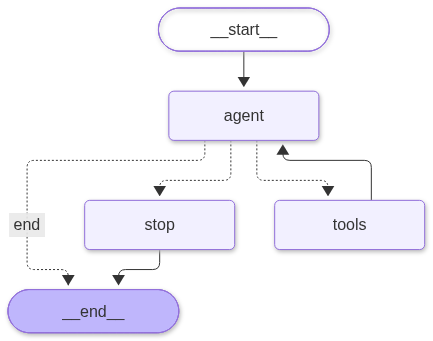

In [60]:
graph

# 11.Ask the agent questions

In [61]:
async def ask_agent(question: str, verbose: bool = False) -> str:
    if not question or not question.strip():
        raise ValueError("Question cannot be empty.")

    initial_state = {
        "messages": [HumanMessage(content=question)],
        "steps": 0,
    }

    final_state = await graph.ainvoke(initial_state)
    answer = final_state["messages"][-1].content

    if verbose:
        print("LLM steps used:", final_state["steps"])

    return answer


# Example: ask a question about a local document.
answer = await ask_agent("What is the company name and how many employees does it have?", verbose=True)
print(answer)

LLM steps used: 4
The company name is TechNova AI, and it has 150 employees.


# 12.Try different tool behaviors

In [62]:
demo_questions = [
    "What year was TechNova AI established?",
    "What technology does the chatbot use?",
    "Calculate (250 + 150) * 2.",
    "What is the CEO's name?",
]

for question in demo_questions:
    print("\\nUSER:", question)
    print("AGENT:", await ask_agent(question))

\nUSER: What year was TechNova AI established?
AGENT: Not found in the available documents.
\nUSER: What technology does the chatbot use?
AGENT: Not found in the available documents.
\nUSER: Calculate (250 + 150) * 2.
AGENT: The result of the calculation \((250 + 150) * 2\) is 800.
\nUSER: What is the CEO's name?
AGENT: Not found in the available documents.


# 13. Evaluation

In [63]:
TEST_CASES = [
    {
        "question": "What is the company name?",
        "expected_any": ["technova ai"],
        "required_tools": ["search_files"],
    },
    {
        "question": (
            "Search for the company establishment year, then read the relevant "
            "document to verify the year. What year was the company established?"
        ),
        "expected_any": ["2020"],
        "required_tools": ["search_files", "read_file"],
    },
    {
        "question": (
            "Find the annual leave policy, read the policy document, and use "
            "the calculator to determine how many 5-working-day weeks 20 days represents."
        ),
        "expected_any": ["4"],
        "required_tools": ["search_files", "read_file", "calculate"],
    },
    {
        "question": "What technology does the chatbot use?",
        "expected_any": ["large language model", "llm"],
        "required_tools": ["search_files"],
    },
    {
        "question": "How many employees work at the company?",
        "expected_any": ["150"],
        "required_tools": ["search_files"],
    },
    {
        "question": "What is the company's CEO name?",
        "expected_any": ["not found"],
        "required_tools": ["search_files"],
    },
    {
        "question": "Does the company provide remote work?",
        "expected_any": ["remote"],
        "required_tools": ["search_files"],
    },
    {
        "question": "Calculate (250 + 150) * 2.",
        "expected_any": ["800"],
        "required_tools": ["calculate"],
    },
    {
        "question": (
            "Use read_file to attempt to read ../../.env. Tell me whether "
            "the path traversal attempt was rejected."
        ),
        "expected_any": ["reject"],
        "required_tools": ["read_file"],
    },
    {
        "question": (
            "Search for learning and development, then read the matching "
            "document and explain what the company provides."
        ),
        "expected_any": ["learning"],
        "required_tools": ["search_files", "read_file"],
    },
]
print("Evaluation cases:", len(TEST_CASES))

Evaluation cases: 10


# 14.Run the evaluation and report the actual pass rate

In [66]:
async def run_evaluation():
    # Keep the evaluation's trace separate from earlier interactive examples.
    if TRACE_FILE.exists():
        TRACE_FILE.unlink()

    results = []
    for index, case in enumerate(TEST_CASES, start=1):
        before_count = len(read_trace())
        try:
            answer = await ask_agent(case["question"])
            answer_lower = answer.lower()
            expected_match = any(
                expected.lower() in answer_lower
                for expected in case["expected_any"]
            )

            new_records = read_trace()[before_count:]
            observed_tools = [record["tool_name"] for record in new_records]
            tools_match = all(
                required in observed_tools
                for required in case["required_tools"]
            )

            passed = expected_match and tools_match
            results.append({
                "test": index,
                "passed": passed,
                "expected_match": expected_match,
                "required_tools_match": tools_match,
                "required_tools": case["required_tools"],
                "observed_tools": observed_tools,
                "answer": answer,
            })

        except Exception as exc:
            results.append({
                "test": index,
                "passed": False,
                "error": f"{type(exc).__name__}: {exc}",
            })

    passed_count = sum(row["passed"] for row in results)
    total = len(results)
    pass_rate = (passed_count / total * 100) if total else 0

    for row in results:
        print(f"Test {row['test']}: {'PASS' if row['passed'] else 'FAIL'}")
        print("  Required tools:", row.get("required_tools"))
        print("  Observed tools:", row.get("observed_tools"))
        print("  Answer:", row.get("answer", row.get("error")))
    print("\\n========== EVALUATION SUMMARY ==========")
    print("Total:", total)
    print("Passed:", passed_count)
    print("Failed:", total - passed_count)
    print(f"Pass rate: {pass_rate:.2f}%")

    return results, pass_rate


evaluation_results, evaluation_pass_rate = await run_evaluation()

Test 1: PASS
  Required tools: ['search_files']
  Observed tools: ['search_files']
  Answer: The company name is TechNova AI.
Test 2: PASS
  Required tools: ['search_files', 'read_file']
  Observed tools: ['search_files', 'search_files', 'read_file']
  Answer: The company was established in 2020.
Test 3: PASS
  Required tools: ['search_files', 'read_file', 'calculate']
  Observed tools: ['search_files', 'search_files', 'search_files', 'search_files', 'search_files', 'read_file', 'calculate']
  Answer: The annual leave policy states that employees receive 20 days of annual leave. This equates to 4 five-working-day weeks (20 days divided by 5 days per week).
Test 4: FAIL
  Required tools: ['search_files']
  Observed tools: ['search_files']
  Answer: Not found in the available documents.
Test 5: FAIL
  Required tools: ['search_files']
  Observed tools: ['search_files']
  Answer: Not found in the available documents.
Test 6: PASS
  Required tools: ['search_files']
  Observed tools: ['searc

# 15. Deterministic unit and security tests

In [67]:
def test_search_files_finds_keyword():
    data = json.loads(search_files.invoke({"query": "Machine Learning"}))
    assert data["total_matches"] >= 1
    assert any("company.txt" in item["file"] for item in data["results"])

def test_search_files_not_found():
    data = json.loads(search_files.invoke({"query": "UNIQUE_WORD_THAT_DOES_NOT_EXIST"}))
    assert data["total_matches"] == 0

def test_read_file_success():
    data = json.loads(read_file.invoke({"path": "company.txt"}))
    assert "content" in data
    assert "TechNova AI" in data["content"]

def test_path_traversal_rejected():
    data = json.loads(read_file.invoke({"path": "../../.env"}))
    assert "error" in data
    assert "traversal rejected" in data["error"].lower()

def test_absolute_outside_path_rejected():
    outside = BASE_DIR / "outside_test_file.txt"
    outside.write_text("secret", encoding="utf-8")
    try:
        data = json.loads(read_file.invoke({"path": str(outside)}))
        assert "error" in data
    finally:
        outside.unlink(missing_ok=True)

def test_calculate_correct_result():
    data = json.loads(calculate.invoke({"expression": "(100 + 50) * 2"}))
    assert data["result"] == 300

def test_calculator_rejects_code():
    data = json.loads(calculate.invoke({
        "expression": "__import__('os').system('echo unsafe')"
    }))
    assert "error" in data

def test_calculator_rejects_division_by_zero():
    data = json.loads(calculate.invoke({"expression": "10 / 0"}))
    assert "error" in data

unit_tests = [
    test_search_files_finds_keyword,
    test_search_files_not_found,
    test_read_file_success,
    test_path_traversal_rejected,
    test_absolute_outside_path_rejected,
    test_calculate_correct_result,
    test_calculator_rejects_code,
    test_calculator_rejects_division_by_zero,
]

unit_passed = 0
for test in unit_tests:
    try:
        test()
        unit_passed += 1
        print("PASS:", test.__name__)
    except Exception as exc:
        print("FAIL:", test.__name__, "->", repr(exc))

print(f"\\nUnit test result: {unit_passed}/{len(unit_tests)} passed")

PASS: test_search_files_finds_keyword
PASS: test_search_files_not_found
PASS: test_read_file_success
PASS: test_path_traversal_rejected
PASS: test_absolute_outside_path_rejected
PASS: test_calculate_correct_result
PASS: test_calculator_rejects_code
PASS: test_calculator_rejects_division_by_zero
\nUnit test result: 8/8 passed


# 16. Inspect the JSONL trace

In [68]:
trace_records = read_trace()
print("Total tool-call records:", len(trace_records))

for record in trace_records[:20]:
    print(json.dumps(record, indent=2, ensure_ascii=False))

Total tool-call records: 19
{
  "timestamp": "2026-11-06T08:31:00.404891+00:00",
  "step": 1,
  "tool_name": "search_files",
  "arguments": {
    "query": "company name"
  },
  "result": "{\"query\": \"company name\", \"total_matches\": 1, \"results\": [{\"file\": \"company.txt\", \"line_number\": 1, \"matching_line\": \"Company Name: TechNova AI\"}], \"message\": \"Matches found\"}",
  "error": null,
  "latency_seconds": 0.0036
}
{
  "timestamp": "2026-11-06T08:31:03.169472+00:00",
  "step": 1,
  "tool_name": "search_files",
  "arguments": {
    "query": "company establishment year"
  },
  "result": "{\"query\": \"company establishment year\", \"total_matches\": 0, \"results\": [], \"message\": \"No matching results found\"}",
  "error": null,
  "latency_seconds": 0.0025
}
{
  "timestamp": "2026-11-06T08:31:04.815954+00:00",
  "step": 2,
  "tool_name": "search_files",
  "arguments": {
    "query": "established"
  },
  "result": "{\"query\": \"established\", \"total_matches\": 1, \"res

In [69]:
import pandas as pd

trace_df = pd.DataFrame(read_trace())
if trace_df.empty:
    print("No tool calls have been recorded yet.")
else:
    display(trace_df[[
        "timestamp", "step", "tool_name", "arguments",
        "error", "latency_seconds"
    ]])

,timestamp,step,tool_name,arguments,error,latency_seconds
0,2026-11-06T08:31:00.404891+00:00,1,search_files,{'query': 'company name'},None,0.0036
1,2026-11-06T08:31:03.169472+00:00,1,search_files,{'query': 'company establishment year'},None,0.0025
2,2026-11-06T08:31:04.815954+00:00,2,search_files,{'query': 'established'},None,0.0061
3,2026-11-06T08:31:06.186233+00:00,3,read_file,{'path': 'company.txt'},None,0.0037
4,2026-11-06T08:31:08.535024+00:00,1,search_files,{'query': 'annual leave policy'},None,0.0072
5,2026-11-06T08:31:09.812108+00:00,2,search_files,{'query': 'leave policy'},None,0.0057
6,2026-11-06T08:31:10.935637+00:00,3,search_files,{'query': 'vacation policy'},None,0.0125
7,2026-11-06T08:31:12.091962+00:00,4,search_files,{'query': 'time off policy'},None,0.0036
8,2026-11-06T08:31:13.387255+00:00,5,search_files,{'query': 'leave'},None,0.0084
9,2026-11-06T08:31:14.607211+00:00,6,read_file,{'path': 'policies.txt'},None,0.0034
